In [32]:
# ========================================
# CONFIGURACIÓN
# ========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path("/mnt/c/Users/danie/OneDrive/Desktop/Proyectos/Automocion/data")
PROCESSED_DIR = DATA_DIR / "processed"

matr_tipo = pd.read_csv(PROCESSED_DIR / "matriculaciones_tipo_limpio.csv")
parque_tipos = pd.read_csv(PROCESSED_DIR / "parque_vehiculos_limpio.csv")
matr_prov = pd.read_csv(PROCESSED_DIR / "matriculaciones_provincia.csv")
matr_gasolina = pd.read_csv(PROCESSED_DIR / "matriculaciones_gasolina.csv")
matr_gasoil = pd.read_csv(PROCESSED_DIR / "matriculaciones_gasoil.csv")
matr_otros = pd.read_csv(PROCESSED_DIR / "matriculaciones_otros.csv")
m_tur_medio = pd.read_csv(PROCESSED_DIR / "distintivo_ambiental.csv")

1. Evolución del mercado automotriz

In [13]:
matr_tipo["turismos_pct"] = matr_tipo["turismos"] / matr_tipo["total"]

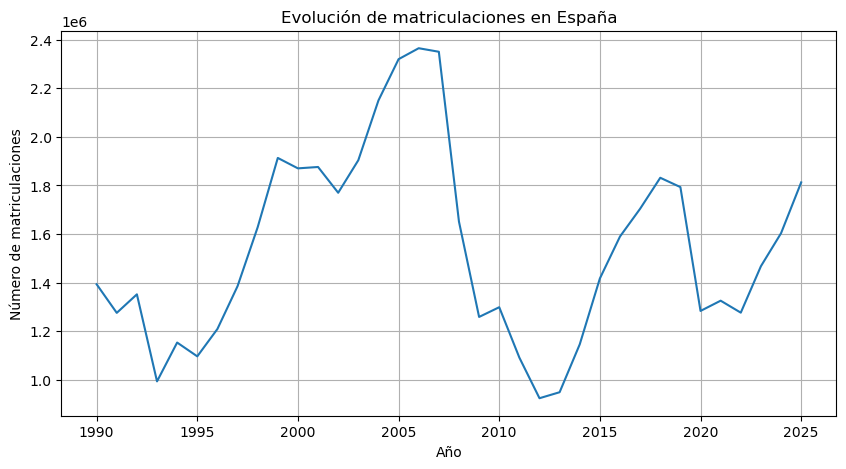

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.plot(matr_tipo["anio"], matr_tipo["total"])
plt.title("Evolución de matriculaciones en España")
plt.xlabel("Año")
plt.ylabel("Número de matriculaciones")
plt.grid(True)
plt.show()
/#Esta tabla te permite analizar:
    #Evolución del mercado automotriz
    #Impacto de crisis (2008, COVID)
    #Crecimiento del mercado
    #Cambios en motocicletas vs turismos
    #Tendencias a largo plazo//

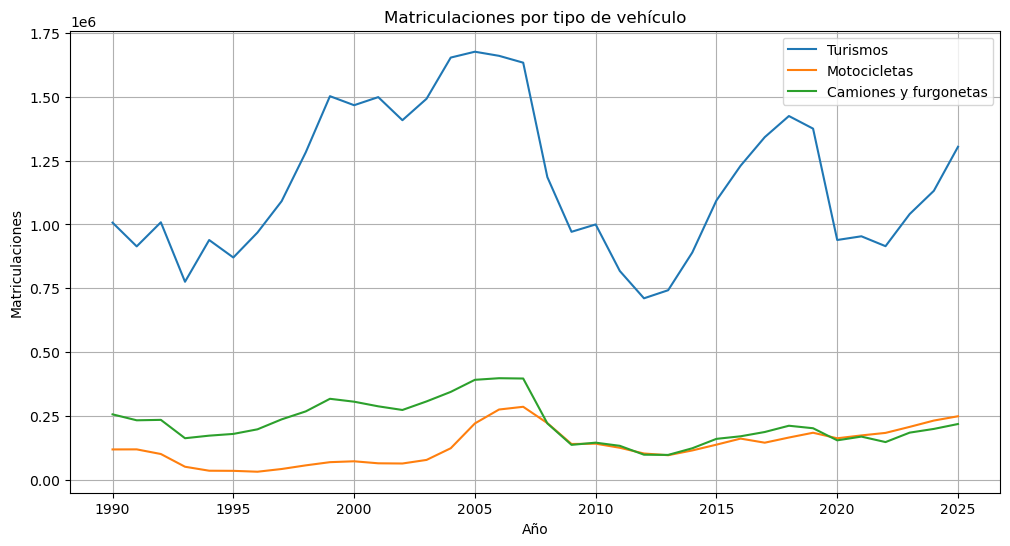

In [25]:
plt.figure(figsize=(12,6))

plt.plot(matr_tipo["anio"], matr_tipo["turismos"], label="Turismos")
plt.plot(matr_tipo["anio"], matr_tipo["motocicletas"], label="Motocicletas")
plt.plot(matr_tipo["anio"], matr_tipo["camiones_furgonetas"], label="Camiones y furgonetas")

plt.title("Matriculaciones por tipo de vehículo")
plt.xlabel("Año")
plt.ylabel("Matriculaciones")
plt.legend()
plt.grid(True)
plt.show()

Cosas interesantes en las graficas:

Año    	Qué pasó
2008	Crisis financiera
2012	Mercado bajo
2020	COVID
2021–2024	Recuperación
Últimos años	Electrificación

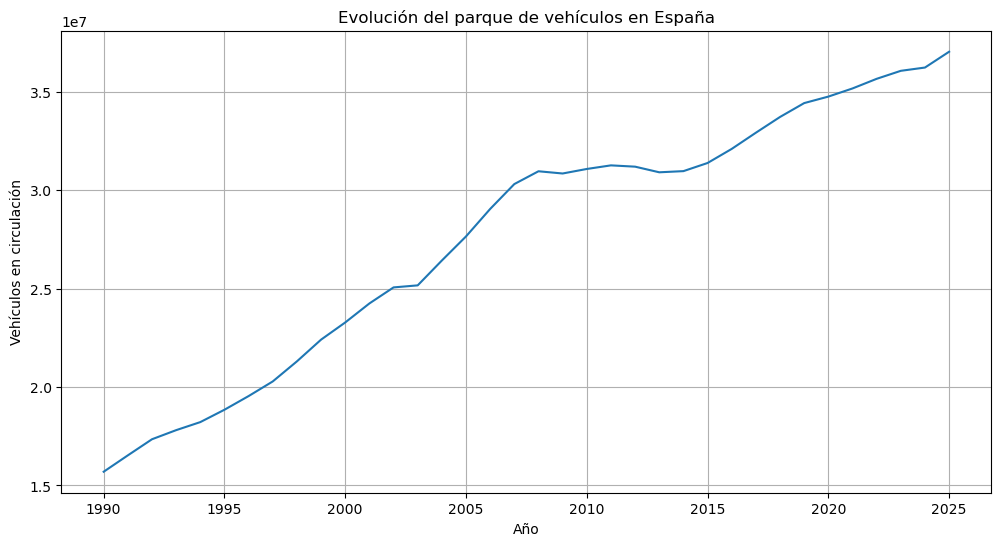

In [15]:
plt.figure(figsize=(12,6))
plt.plot(parque_tipos["anio"], parque_tipos["total"])
plt.title("Evolución del parque de vehículos en España")
plt.xlabel("Año")
plt.ylabel("Vehículos en circulación")
plt.grid(True)
plt.show()

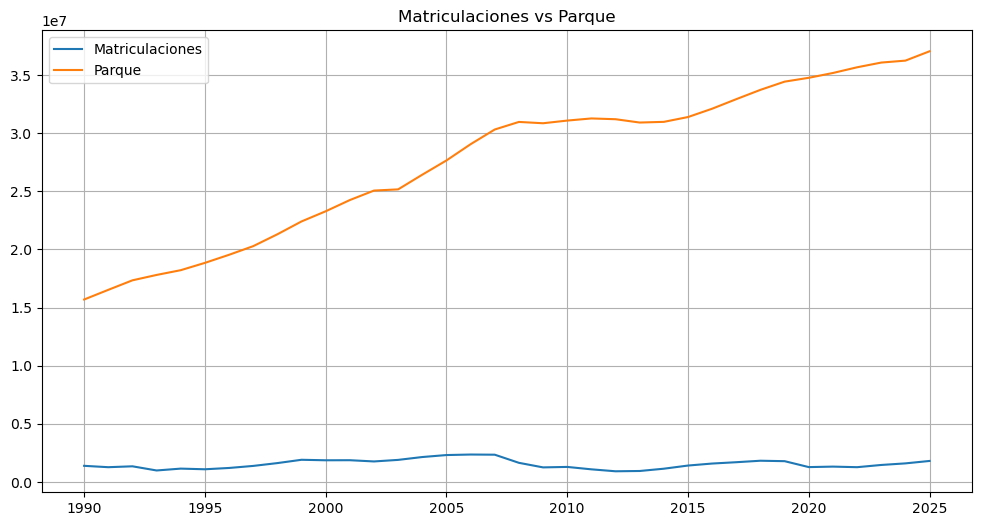

In [16]:
comparacion = matr_tipo.merge(
    parque_tipos[["anio", "total"]],
    on="anio",
    suffixes=("_matriculaciones", "_parque")
)

plt.figure(figsize=(12,6))
plt.plot(comparacion["anio"], comparacion["total_matriculaciones"], label="Matriculaciones")
plt.plot(comparacion["anio"], comparacion["total_parque"], label="Parque")

plt.legend()
plt.title("Matriculaciones vs Parque")
plt.grid(True)
plt.show()

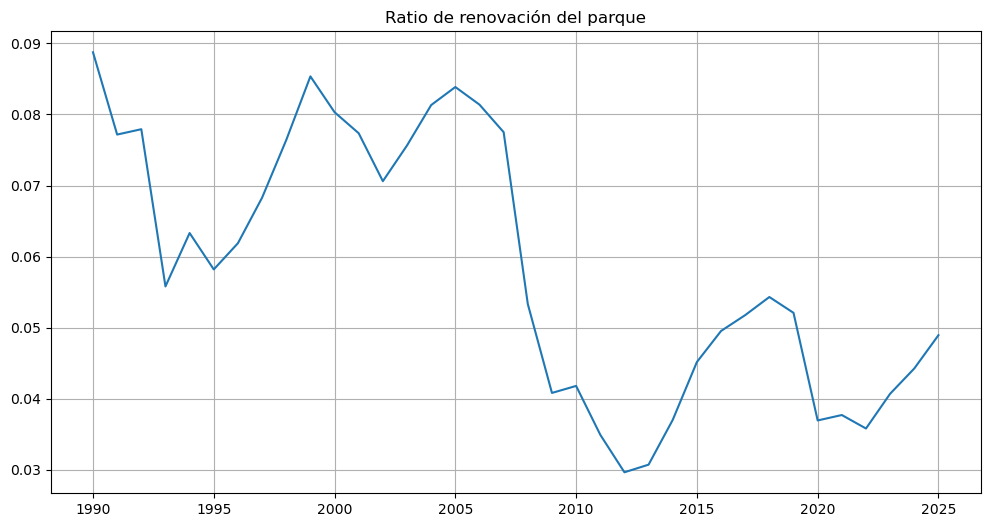

In [ ]:
#interesante a nivel negocio:
#Ratio = matriculaciones / parque
#Indica qué % del parque se renueva cada año.
comparacion["ratio"] = comparacion["total_matriculaciones"] / comparacion["total_parque"]

plt.figure(figsize=(12,6))
plt.plot(comparacion["anio"], comparacion["ratio"])
plt.title("Ratio de renovación del parque")
plt.grid(True)
plt.show()

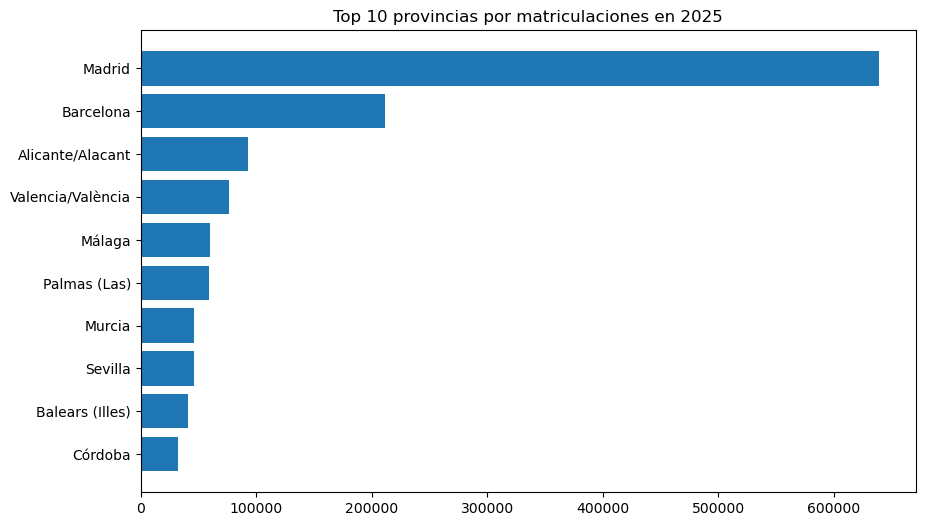

In [24]:
ultimo_anio = matr_prov_long["anio"].max()

top_prov = (
    matr_prov_long[matr_prov_long["anio"] == ultimo_anio]
    .sort_values("matriculaciones", ascending=False)
    .head(10)
)

plt.figure(figsize=(10,6))
plt.barh(top_prov["provincia"], top_prov["matriculaciones"])
plt.title(f"Top 10 provincias por matriculaciones en {ultimo_anio}")
plt.gca().invert_yaxis()
plt.show()

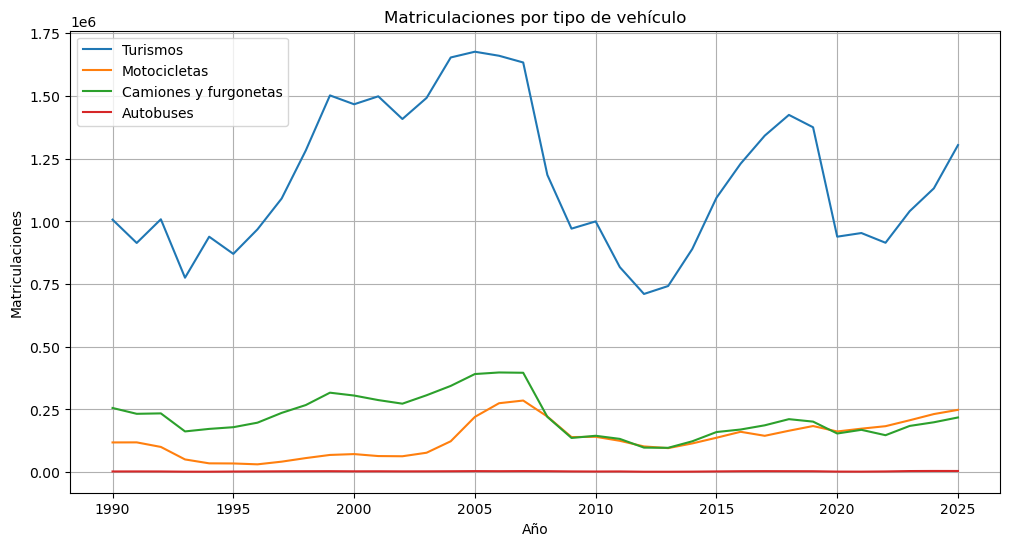

In [26]:
plt.figure(figsize=(12,6))

plt.plot(matr_tipo["anio"], matr_tipo["turismos"], label="Turismos")
plt.plot(matr_tipo["anio"], matr_tipo["motocicletas"], label="Motocicletas")
plt.plot(matr_tipo["anio"], matr_tipo["camiones_furgonetas"], label="Camiones y furgonetas")
plt.plot(matr_tipo["anio"], matr_tipo["autobuses"], label="Autobuses")

plt.legend()
plt.title("Matriculaciones por tipo de vehículo")
plt.xlabel("Año")
plt.ylabel("Matriculaciones")
plt.grid(True)
plt.show()

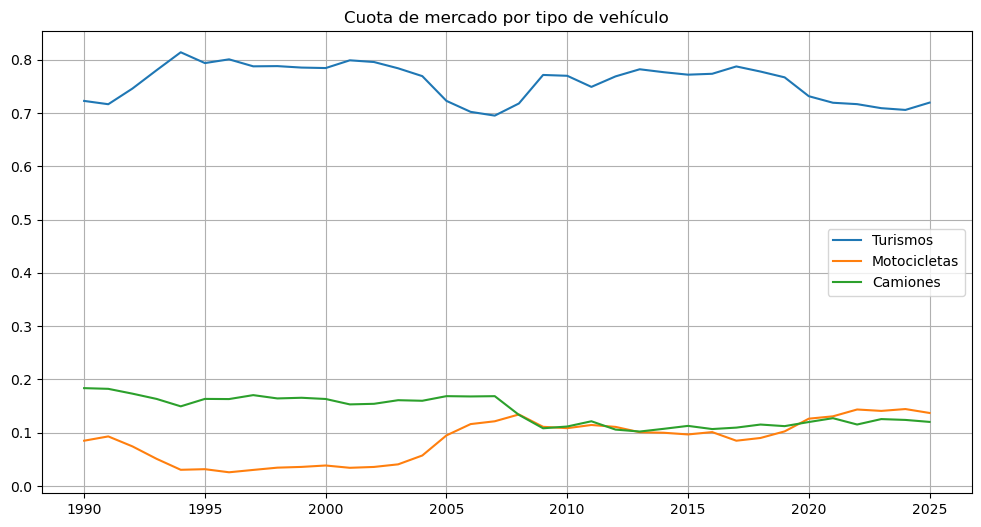

In [27]:
matr_tipo["pct_turismos"] = matr_tipo["turismos"] / matr_tipo["total"]
matr_tipo["pct_motos"] = matr_tipo["motocicletas"] / matr_tipo["total"]
matr_tipo["pct_camiones"] = matr_tipo["camiones_furgonetas"] / matr_tipo["total"]

plt.figure(figsize=(12,6))
plt.plot(matr_tipo["anio"], matr_tipo["pct_turismos"], label="Turismos")
plt.plot(matr_tipo["anio"], matr_tipo["pct_motos"], label="Motocicletas")
plt.plot(matr_tipo["anio"], matr_tipo["pct_camiones"], label="Camiones")

plt.legend()
plt.title("Cuota de mercado por tipo de vehículo")
plt.grid(True)
plt.show()

In [ ]:
#creo tabla de combustibles para analisis
combustible = matr_gasolina[["anio", "total"]].merge(
    matr_gasoil[["anio", "total"]],
    on="anio",
    suffixes=("_gasolina", "_gasoil")
)

combustible = combustible.merge(
    matr_otros[["anio", "total"]],
    on="anio",
    how="left"
)

combustible = combustible.rename(columns={"total": "otros"})
combustible = combustible.fillna(0)

combustible.head()

,anio,total_gasolina,total_gasoil,otros
0,1990,1060702,332544,0.0
1,1991,980241,295339,0.0
2,1992,1007648,344190,0.0
3,1993,699873,293766,0.0
4,1994,761172,392250,0.0


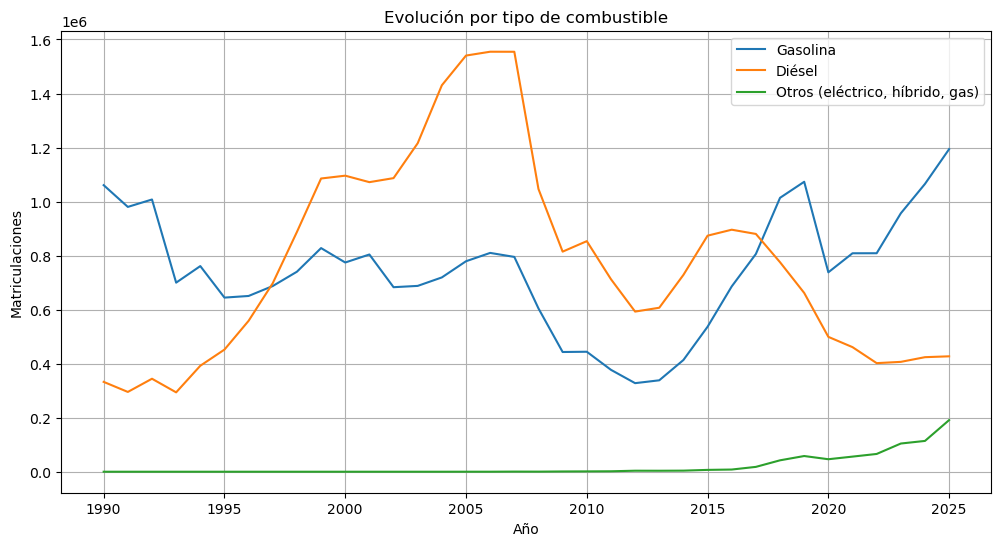

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

plt.plot(combustible["anio"], combustible["total_gasolina"], label="Gasolina")
plt.plot(combustible["anio"], combustible["total_gasoil"], label="Diésel")
plt.plot(combustible["anio"], combustible["otros"], label="Otros (eléctrico, híbrido, gas)")

plt.legend()
plt.title("Evolución por tipo de combustible")
plt.xlabel("Año")
plt.ylabel("Matriculaciones")
plt.grid(True)
plt.show()

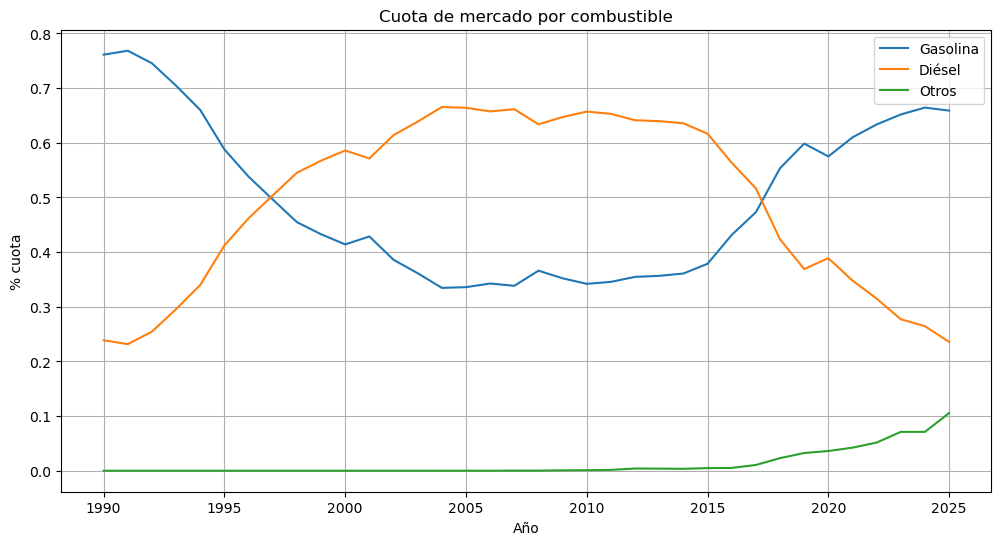

In [31]:
combustible["total"] = (
    combustible["total_gasolina"] +
    combustible["total_gasoil"] +
    combustible["otros"]
)

combustible["pct_gasolina"] = combustible["total_gasolina"] / combustible["total"]
combustible["pct_gasoil"] = combustible["total_gasoil"] / combustible["total"]
combustible["pct_otros"] = combustible["otros"] / combustible["total"]

plt.figure(figsize=(12,6))
plt.plot(combustible["anio"], combustible["pct_gasolina"], label="Gasolina")
plt.plot(combustible["anio"], combustible["pct_gasoil"], label="Diésel")
plt.plot(combustible["anio"], combustible["pct_otros"], label="Otros")

plt.legend()
plt.title("Cuota de mercado por combustible")
plt.xlabel("Año")
plt.ylabel("% cuota")
plt.grid(True)
plt.show()

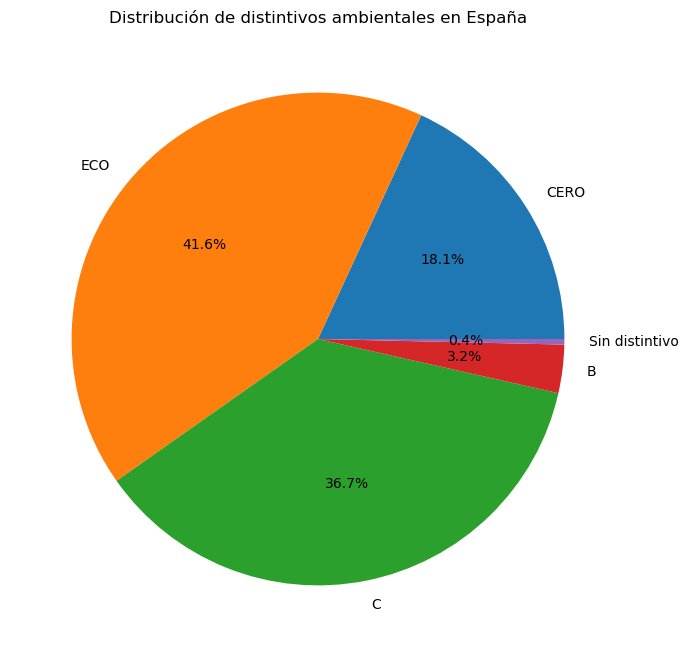

In [33]:
import matplotlib.pyplot as plt

totales = [
    m_tur_medio["CERO"].sum(),
    m_tur_medio["ECO"].sum(),
    m_tur_medio["C"].sum(),
    m_tur_medio["B"].sum(),
    m_tur_medio["Sin distintivo"].sum()
]

labels = ["CERO", "ECO", "C", "B", "Sin distintivo"]

plt.figure(figsize=(8,8))
plt.pie(totales, labels=labels, autopct='%1.1f%%')
plt.title("Distribución de distintivos ambientales en España")
plt.show()

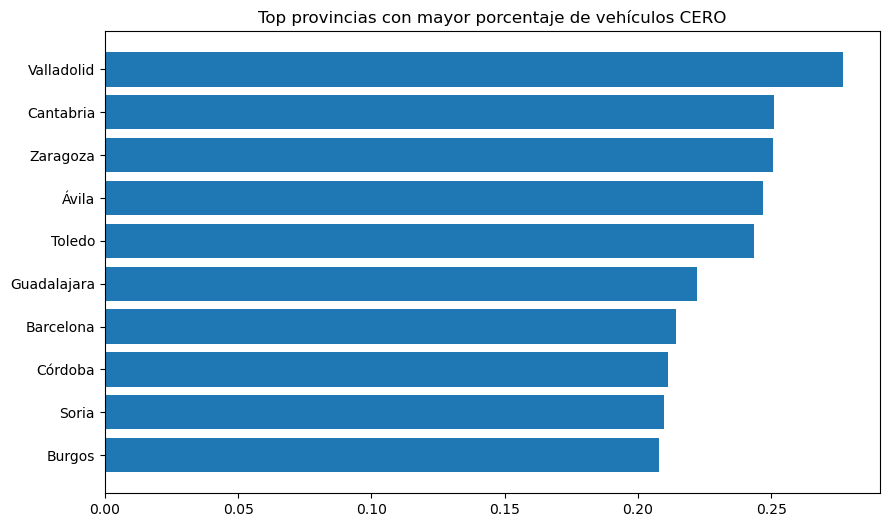

In [ ]:
#donde hay mas coches electricos
top_cero = m_tur_medio.sort_values("pct_cero", ascending=False).head(10)

plt.figure(figsize=(10,6))
plt.barh(top_cero["provincia"], top_cero["pct_cero"])
plt.title("Top provincias con mayor porcentaje de vehículos CERO")
plt.gca().invert_yaxis()
plt.show()

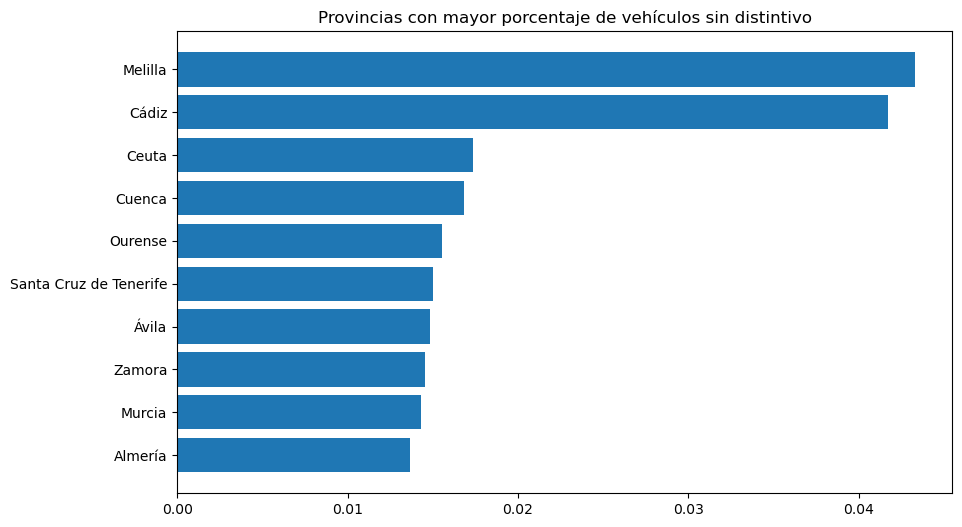

In [ ]:
#donde hay mas coches viejos
top_viejos = m_tur_medio.sort_values("pct_sin", ascending=False).head(10)

plt.figure(figsize=(10,6))
plt.barh(top_viejos["provincia"], top_viejos["pct_sin"])
plt.title("Provincias con mayor porcentaje de vehículos sin distintivo")
plt.gca().invert_yaxis()
plt.show()